# 05 Temporal Analysis

**Objective:** describe how Airbnb rental rates change over time using citywide medians of `avg_daily_rate`, in three parts: (A) monthly trend March 2021 to February 2026, (B) seasonal pattern using the complete years 2022-2025, and (C) yearly comparison for 2022-2025.

**Data:** all 150,034 listing-month records from `past_rates_clean.parquet` (the temporal analysis is citywide, so records excluded from the spatial analysis are kept).

**Caution:** the set of listings changes from month to month, so a change in the median can reflect which listings are present as well as price movement. Rates are nominal USD.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = PROJECT_ROOT / "data" / "processed"
FIG = PROJECT_ROOT / "outputs" / "figures"
TAB = PROJECT_ROOT / "outputs" / "tables"
for p in (FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(PROCESSED / "past_rates_clean.parquet")
print("Rows:", len(df), "| Listings:", df["listing_id"].nunique(), "| Months:", df["month_date"].nunique())

Rows: 150034 | Listings: 4266 | Months: 60


In [2]:
monthly = (df.groupby("month_date")
             .agg(median_rate=("avg_daily_rate", "median"),
                  mean_rate=("avg_daily_rate", "mean"),
                  n_listings=("listing_id", "nunique"))
             .reset_index())

print("Months:", len(monthly))
print()
print("First 3 and last 3 months:")
print(pd.concat([monthly.head(3), monthly.tail(3)]).to_string(index=False, float_format=lambda v: f"{v:.1f}"))
print()
hi, lo = monthly.loc[monthly["median_rate"].idxmax()], monthly.loc[monthly["median_rate"].idxmin()]
print(f"Highest monthly median: ${hi['median_rate']:.1f} in {hi['month_date']:%B %Y}")
print(f"Lowest monthly median:  ${lo['median_rate']:.1f} in {lo['month_date']:%B %Y}")
print(f"Listings contributing per month: min {monthly['n_listings'].min()}, max {monthly['n_listings'].max()}")

monthly.to_csv(TAB / "05_monthly_median_rate.csv", index=False)

Months: 60

First 3 and last 3 months:
month_date  median_rate  mean_rate  n_listings
2021-03-01        108.5      146.0        2505
2021-04-01        110.9      148.5        2505
2021-05-01        115.7      152.7        2505
2025-12-01        163.4      221.5        1625
2026-01-01        155.7      202.8        1625
2026-02-01        158.5      203.2        1625

Highest monthly median: $163.6 in November 2025
Lowest monthly median:  $108.5 in March 2021
Listings contributing per month: min 1369, max 3187


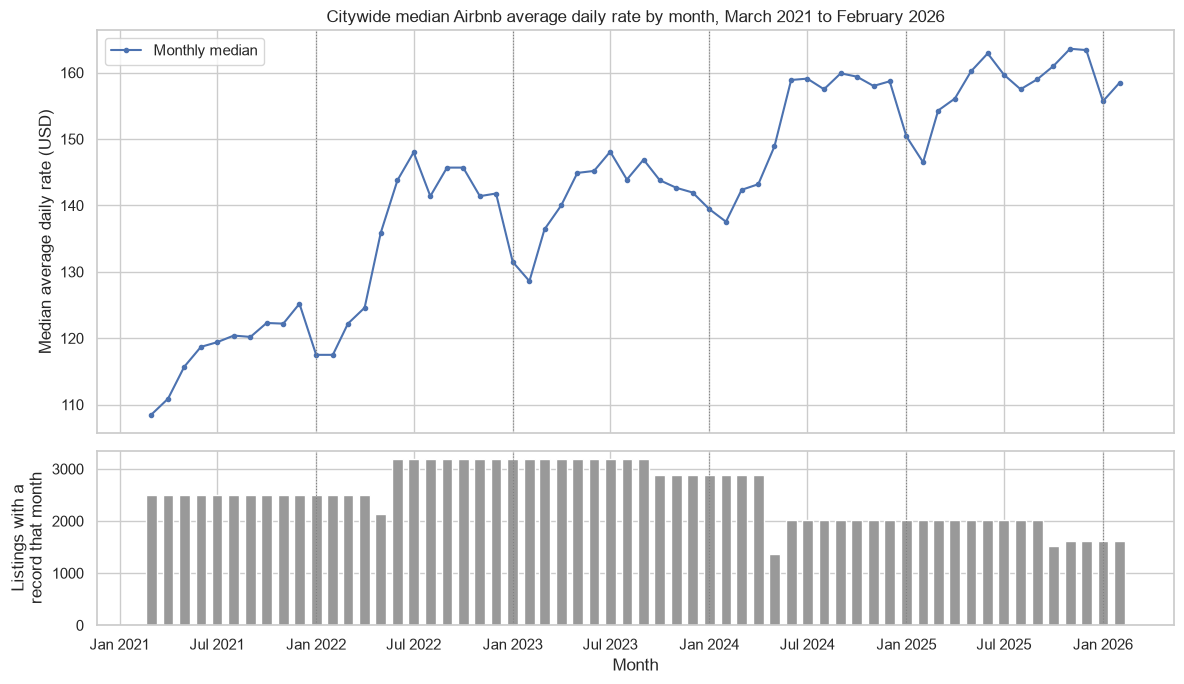

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})

ax1.plot(monthly["month_date"], monthly["median_rate"], marker="o", markersize=3, color="#4C72B0", label="Monthly median")
ax1.set_title("Citywide median Airbnb average daily rate by month, March 2021 to February 2026")
ax1.set_ylabel("Median average daily rate (USD)")
ax1.legend(loc="upper left")

ax2.bar(monthly["month_date"], monthly["n_listings"], width=20, color="#999999")
ax2.set_ylabel("Listings with a\nrecord that month")
ax2.set_xlabel("Month")
ax2.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

for ax in (ax1, ax2):
    for y in range(2022, 2027):
        ax.axvline(pd.Timestamp(f"{y}-01-01"), color="grey", linestyle=":", linewidth=0.8)

plt.tight_layout()
plt.savefig(FIG / "05_monthly_trend.png", dpi=150, bbox_inches="tight")
plt.show()

## Robustness check: fixed set of listings
The monthly median is repeated using only listings that have a record in every month of the study period, so changes cannot be caused by listings entering or leaving the data. This subset may be small and may not be typical of all listings, so it is a check, not a replacement for the main series.

Listings present in all 60 months: 711 of 4266

First and last month, both series (USD):
month_date  median_rate  median_fixed
2021-03-01        108.5         111.9
2021-04-01        110.9         112.6
2026-01-01        155.7         143.8
2026-02-01        158.5         142.6
Change first to last month: all listings +46.1% | fixed set +27.4%
Correlation between the two series: 0.96


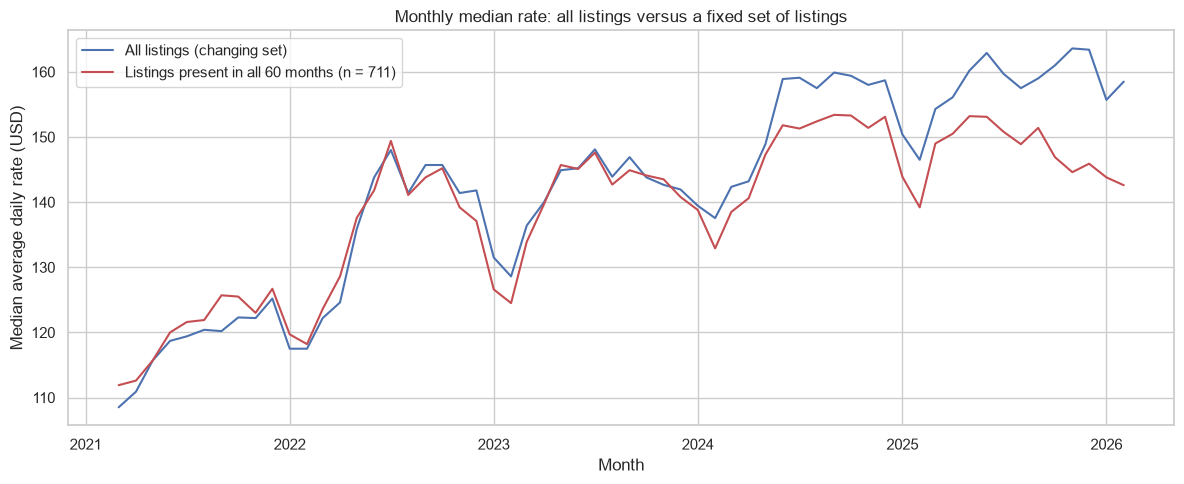

In [4]:
n_months = df["month_date"].nunique()
cnt = df.groupby("listing_id")["month_date"].nunique()
full_ids = cnt[cnt == n_months].index
print(f"Listings present in all {n_months} months: {len(full_ids)} of {df['listing_id'].nunique()}")

if len(full_ids) >= 30:
    fixed = df[df["listing_id"].isin(full_ids)]
    mf = fixed.groupby("month_date")["avg_daily_rate"].median().rename("median_fixed").reset_index()
    cmp = monthly[["month_date", "median_rate"]].merge(mf, on="month_date")

    print()
    print("First and last month, both series (USD):")
    print(pd.concat([cmp.head(2), cmp.tail(2)]).to_string(index=False, float_format=lambda v: f"{v:.1f}"))
    first, last = cmp.iloc[0], cmp.iloc[-1]
    print(f"Change first to last month: all listings {100*(last['median_rate']/first['median_rate']-1):+.1f}% | fixed set {100*(last['median_fixed']/first['median_fixed']-1):+.1f}%")
    print("Correlation between the two series:", round(cmp["median_rate"].corr(cmp["median_fixed"]), 2))

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(cmp["month_date"], cmp["median_rate"], color="#4C72B0", label="All listings (changing set)")
    ax.plot(cmp["month_date"], cmp["median_fixed"], color="#C44E52", label=f"Listings present in all {n_months} months (n = {len(full_ids)})")
    ax.set_title("Monthly median rate: all listings versus a fixed set of listings")
    ax.set_xlabel("Month")
    ax.set_ylabel("Median average daily rate (USD)")
    ax.legend()
    plt.tight_layout()
    plt.savefig(FIG / "05_monthly_trend_fixed_listings.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Too few listings to make a meaningful fixed-set comparison.")

## B. Seasonal analysis (complete years 2022-2025)
For each year, the median rate is calculated for each calendar month. To remove the effect of the overall trend, each monthly median is divided by the average of that year's twelve monthly medians (index = 100 means an average month for that year). A month is described as consistently high or low only if it is above or below 100 in most of the four years. A fixed set of listings (present in all 48 months of 2022-2025) is used as a robustness check.

In [5]:
import calendar
YEARS = [2022, 2023, 2024, 2025]
cy = df[df["year"].isin(YEARS)]

def seasonal_tables(data):
    mm = data.groupby(["month", "year"])["avg_daily_rate"].median().unstack("year")   # 12 months x 4 years
    idx = 100 * mm / mm.mean()          # each year's twelve monthly medians average 100
    return mm, idx

mm, idx = seasonal_tables(cy)
summary = pd.DataFrame({"mean_index": idx.mean(axis=1), "min_index": idx.min(axis=1),
                        "max_index": idx.max(axis=1), "years_above_100": (idx > 100).sum(axis=1)})
mlabels = [calendar.month_abbr[m] for m in summary.index]
summary.index = mlabels

print("Monthly median rate (USD) by calendar month and year:")
m_print = mm.copy(); m_print.index = mlabels
print(m_print.round(1).to_string())
print()
print("Seasonal index (100 = an average month for that year):")
print(summary.round(1).to_string())
summary.to_csv(TAB / "05_seasonal_index_2022_2025.csv")

Monthly median rate (USD) by calendar month and year:
year   2022   2023   2024   2025
Jan   117.5  131.5  139.4  150.4
Feb   117.5  128.6  137.6  146.5
Mar   122.2  136.4  142.4  154.3
Apr   124.6  140.0  143.2  156.1
May   135.9  144.9  148.9  160.2
Jun   143.8  145.2  158.9  162.9
Jul   148.0  148.1  159.1  159.7
Aug   141.4  143.9  157.5  157.5
Sep   145.7  146.9  159.9  159.0
Oct   145.7  143.8  159.4  161.0
Nov   141.4  142.6  158.0  163.6
Dec   141.8  142.0  158.7  163.4

Seasonal index (100 = an average month for that year):
     mean_index  min_index  max_index  years_above_100
Jan        91.7       86.7       95.3                0
Feb        90.3       86.7       92.8                0
Mar        94.6       90.2       97.7                0
Apr        96.1       92.0       99.2                0
May       100.6       98.0      102.7                3
Jun       104.2      102.9      106.2                4
Jul       105.0      101.2      109.3                4
Aug       102.4      

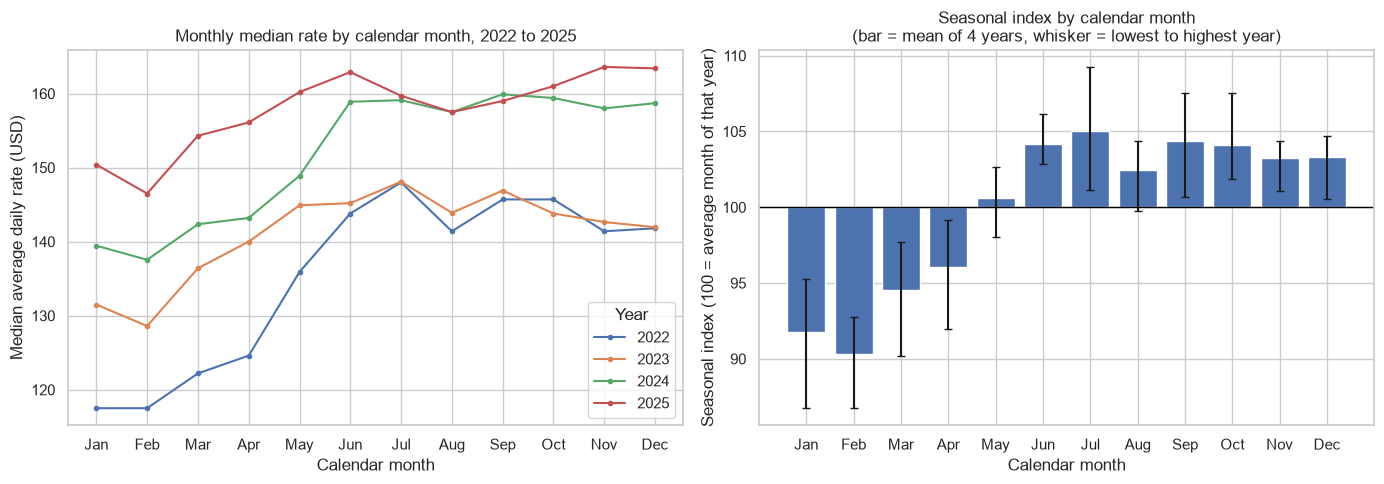

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for y in YEARS:
    ax1.plot(mlabels, mm[y].values, marker="o", markersize=3, label=str(y))
ax1.set_title("Monthly median rate by calendar month, 2022 to 2025")
ax1.set_xlabel("Calendar month")
ax1.set_ylabel("Median average daily rate (USD)")
ax1.legend(title="Year")

err = [summary["mean_index"] - summary["min_index"], summary["max_index"] - summary["mean_index"]]
ax2.bar(mlabels, summary["mean_index"] - 100, bottom=100, yerr=err, capsize=3, color="#4C72B0")
ax2.axhline(100, color="black", linewidth=1)
ax2.set_title("Seasonal index by calendar month\n(bar = mean of 4 years, whisker = lowest to highest year)")
ax2.set_xlabel("Calendar month")
ax2.set_ylabel("Seasonal index (100 = average month of that year)")

plt.tight_layout()
plt.savefig(FIG / "05_seasonal_pattern.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
cnt = cy.groupby("listing_id")["month_date"].nunique()
ids = cnt[cnt == 48].index
print(f"Listings present in all 48 months of 2022-2025: {len(ids)} of {cy['listing_id'].nunique()}")

if len(ids) >= 30:
    mm_f, idx_f = seasonal_tables(cy[cy["listing_id"].isin(ids)])
    comp = pd.DataFrame({"index_all": idx.mean(axis=1), "index_fixed": idx_f.mean(axis=1),
                         "yrs_above_100_all": (idx > 100).sum(axis=1), "yrs_above_100_fixed": (idx_f > 100).sum(axis=1)})
    comp.index = mlabels
    print(comp.round(1).to_string())
    print("Correlation between the two seasonal patterns:", round(comp["index_all"].corr(comp["index_fixed"]), 2))
else:
    print("Too few listings for a fixed-set comparison.")

Listings present in all 48 months of 2022-2025: 711 of 4266
     index_all  index_fixed  yrs_above_100_all  yrs_above_100_fixed
Jan       91.7         92.6                  0                    0
Feb       90.3         90.1                  0                    0
Mar       94.6         95.4                  0                    1
Apr       96.1         98.0                  0                    1
May      100.6        102.3                  3                    4
Jun      104.2        103.7                  4                    4
Jul      105.0        105.1                  4                    4
Aug      102.4        102.6                  3                    4
Sep      104.4        104.1                  4                    4
Oct      104.1        103.4                  4                    3
Nov      103.3        101.5                  4                    3
Dec      103.3        101.1                  4                    3
Correlation between the two seasonal patterns: 0.97


## C. Yearly comparison (complete years 2022-2025)
Yearly median rates are calculated three ways: (1) all listing-month records, (2) the median of listing-level annual medians (the method used in the spatial analysis), and (3) a fixed set of listings present in every month of 2022-2025. 2021 and 2026 are partial years and are not compared. Percentage changes are in nominal USD.

In [8]:
cy = df[df["year"].isin(YEARS)]
ly = cy.groupby(["listing_id", "year"])["avg_daily_rate"].median().reset_index()

cnt = cy.groupby("listing_id")["month_date"].nunique()
ids = cnt[cnt == 48].index
cnt60 = df.groupby("listing_id")["month_date"].nunique()
print("Fixed set for 2022-2025 identical to the 60-month set?", set(ids) == set(cnt60[cnt60 == 60].index))

yearly = pd.concat([
    ly.groupby("year")["listing_id"].nunique().rename("listings"),
    cy.groupby("year")["avg_daily_rate"].median().rename("all_records"),
    ly.groupby("year")["avg_daily_rate"].median().rename("listing_level"),
    cy[cy["listing_id"].isin(ids)].groupby("year")["avg_daily_rate"].median().rename("fixed_set"),
], axis=1)

print("Yearly median rate (USD):")
print(yearly.round(1).to_string())

methods = ["all_records", "listing_level", "fixed_set"]
print("\nYear-to-year change (%):")
print((yearly[methods].pct_change() * 100).round(1).dropna().to_string())
print("\nChange 2022 to 2025 (%):")
print((100 * (yearly.loc[2025, methods] / yearly.loc[2022, methods] - 1)).round(1).to_string())

yearly.to_csv(TAB / "05_yearly_medians_2022_2025.csv")

Fixed set for 2022-2025 identical to the 60-month set? True
Yearly median rate (USD):
      listings  all_records  listing_level  fixed_set
year                                                 
2022      3555        134.8          137.0      134.0
2023      3193        140.9          142.3      140.0
2024      3526        150.7          152.0      145.9
2025      2114        157.3          162.8      148.1

Year-to-year change (%):
      all_records  listing_level  fixed_set
year                                       
2023          4.5            3.9        4.5
2024          7.0            6.8        4.2
2025          4.4            7.1        1.5

Change 2022 to 2025 (%):
all_records      16.7
listing_level    18.9
fixed_set        10.5


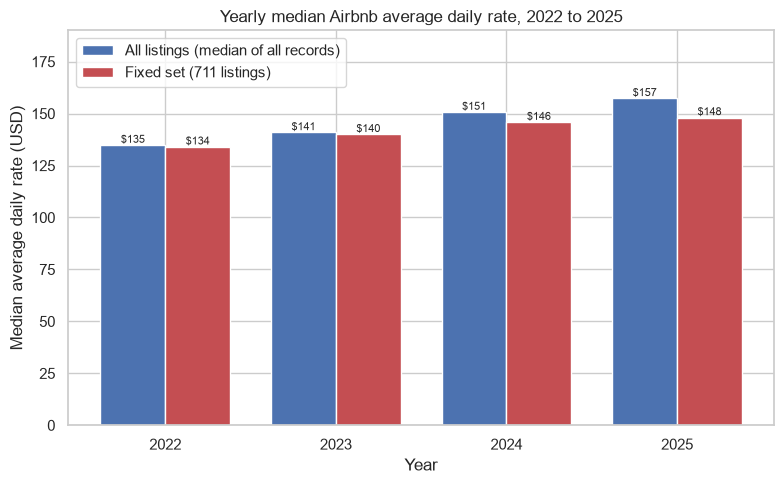

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
w = 0.38
x = np.arange(len(YEARS))
b1 = ax.bar(x - w/2, yearly["all_records"], w, label="All listings (median of all records)", color="#4C72B0")
b2 = ax.bar(x + w/2, yearly["fixed_set"], w, label=f"Fixed set ({len(ids)} listings)", color="#C44E52")
ax.bar_label(b1, fmt="$%.0f", fontsize=8)
ax.bar_label(b2, fmt="$%.0f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(YEARS)
ax.set_title("Yearly median Airbnb average daily rate, 2022 to 2025")
ax.set_xlabel("Year")
ax.set_ylabel("Median average daily rate (USD)")
ax.set_ylim(0, 190)
ax.legend(loc="upper left", ncol=1)
plt.tight_layout()
plt.savefig(FIG / "05_yearly_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary
- **Monthly trend (March 2021 to February 2026):** the citywide median rose from $108.5 (March 2021) to $158.5 (February 2026), +46.1%. The highest monthly median was $163.6 (November 2025). Recurring dips occur around the start of each year.
- **Changing listing set:** the number of listings with a record per month ranged from 1,369 to 3,187 and changed in steps. Using the 711 listings present in all 60 months, the first-to-last-month rise was +27.4% (correlation with the main series 0.96); the two series diverge after mid-2024.
- **Seasonality (2022-2025):** January to April were below an average month in all four years (seasonal index 90.3 to 96.1, lowest in February); June, July and September to December were above in all four years (103.3 to 105.0, highest in July); May and August were above in three of four years. A fixed set of the same 711 listings gave a very similar pattern (r = 0.97). Rates fell from December to the following January in every year boundary.
- **Yearly medians (all records):** $134.8 (2022), $140.9 (2023), $150.7 (2024), $157.3 (2025): +16.7% from 2022 to 2025 (listing-level +18.9%; fixed set +10.5%).

## Limitations / observations
- The listings in the data change over time; the fixed-set checks show the upward trend and the seasonal pattern persist, but part of the headline rise is associated with changes in which listings are observed.
- The fixed set (711 of 4,266 listings) may not be representative of all listings.
- Only four complete years are available, so the seasonal pattern is described as recurring, not established. No causes were tested.
- Rates are nominal USD and not adjusted for inflation.